In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import matplotlib.dates as mdates 
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from glob import glob

In [41]:
telemetry_path = '../data/PdM_telemetry.csv'
failures_path = '../data/PdM_failures.csv'
errors_path = '../data/PdM_errors.csv'

In [7]:
telemetry_df = pd.read_csv(telemetry_path)
telemetry_df.head()

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


In [42]:
errors_df = pd.read_csv(errors_path)
errors_df.head()

,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4


In [8]:
failures_df = pd.read_csv(failures_path)
failures_df.head()

,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4


In [9]:
telemetry_df["datetime"] = pd.to_datetime(telemetry_df["datetime"])
failures_df["datetime"] = pd.to_datetime(failures_df["datetime"])

In [14]:
nan_counts = telemetry_df.isnull().sum()
nan_percentages = (telemetry_df.isnull().sum() / len(telemetry_df)) * 100

nan_report = pd.DataFrame(
    {"Количество NaN": nan_counts, "Процент NaN (%)": nan_percentages}
)
print(nan_report)
print("-" * 50)

           Количество NaN  Процент NaN (%)
datetime                0              0.0
machineID               0              0.0
volt                    0              0.0
rotate                  0              0.0
pressure                0              0.0
vibration               0              0.0
--------------------------------------------------


In [ ]:
m1_telemetry = telemetry_df[telemetry_df["machineID"] == 1].sort_values("datetime")
m1_failures = failures_df[failures_df["machineID"] == 1]

m1_merged = pd.merge(
    m1_telemetry,
    m1_failures,
    on=["datetime", "machineID"],
    how="left",
    suffixes=("", "_fail"),
)

failures_points = m1_merged[m1_merged["failure"].notna()]

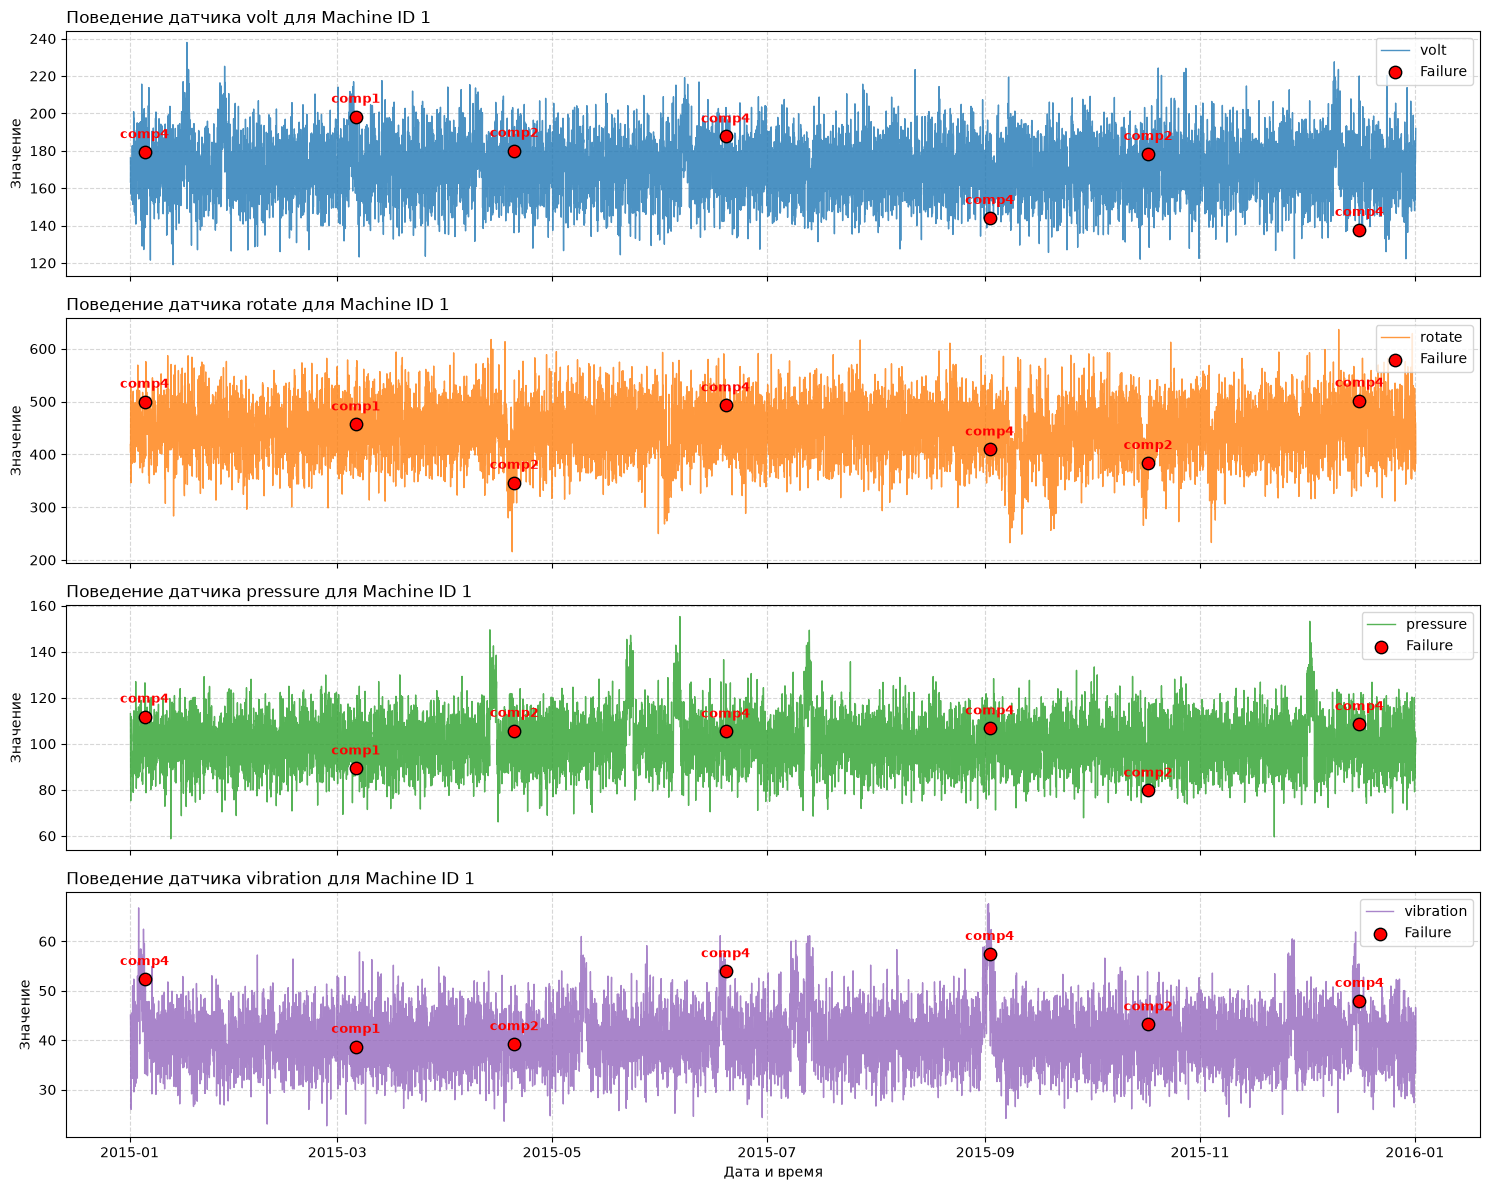

In [12]:
sensors = ["volt", "rotate", "pressure", "vibration"]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"]

fig, axes = plt.subplots(
    nrows=4, ncols=1, figsize=(15, 12), sharex=True, dpi=100
)

for i, sensor in enumerate(sensors):
    ax = axes[i]

    # Линия показаний датчика
    ax.plot(
        m1_merged["datetime"],
        m1_merged[sensor],
        color=colors[i],
        label=sensor,
        alpha=0.8,
        linewidth=1,
    )

    # Красные точки в моменты поломок
    if not failures_points.empty:
        ax.scatter(
            failures_points["datetime"],
            failures_points[sensor],
            color="red",
            s=80,
            zorder=5,
            label="Failure",
            edgecolor="black",
        )

        # Текстовая аннотация над точкой (какой именно компонент сломался)
        for idx, row in failures_points.iterrows():
            ax.annotate(
                row["failure"],
                (row["datetime"], row[sensor]),
                textcoords="offset points",
                xytext=(0, 10),
                ha="center",
                color="red",
                weight="bold",
                fontsize=9,
            )

    ax.set_title(
        f"Поведение датчика {sensor} для Machine ID 1",
        fontsize=12,
        loc="left",
    )
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right")
    ax.set_ylabel("Значение")

plt.xlabel("Дата и время")
plt.tight_layout()
plt.show()

In [27]:
LEAD_TIME_MAX_HRS = 36
LEAD_TIME_MIN_HRS = 18

WIN_SIZE = 24
STEP_SIZE = 1

TARGET_MACHINE_ID = 1

WINDOW_SHORT_H = 3
WINDOW_LONG_H = 24

In [20]:
m1_telemetry = telemetry_df[telemetry_df["machineID"] == TARGET_MACHINE_ID].sort_values("datetime")
m1_failures = failures_df[failures_df["machineID"] == TARGET_MACHINE_ID]

In [21]:
first_failure = m1_failures.iloc[0]
fail_time = first_failure["datetime"]
failed_component = first_failure["failure"]

start_warning_zone = fail_time - pd.Timedelta(hours=LEAD_TIME_MAX_HRS)
end_warning_zone = fail_time - pd.Timedelta(hours=LEAD_TIME_MIN_HRS)

plot_start = fail_time - pd.Timedelta(days=5)
plot_end = fail_time + pd.Timedelta(hours=12)

m1_slice = m1_telemetry[(m1_telemetry["datetime"] >= plot_start) & (m1_telemetry["datetime"] <= plot_end)].copy()

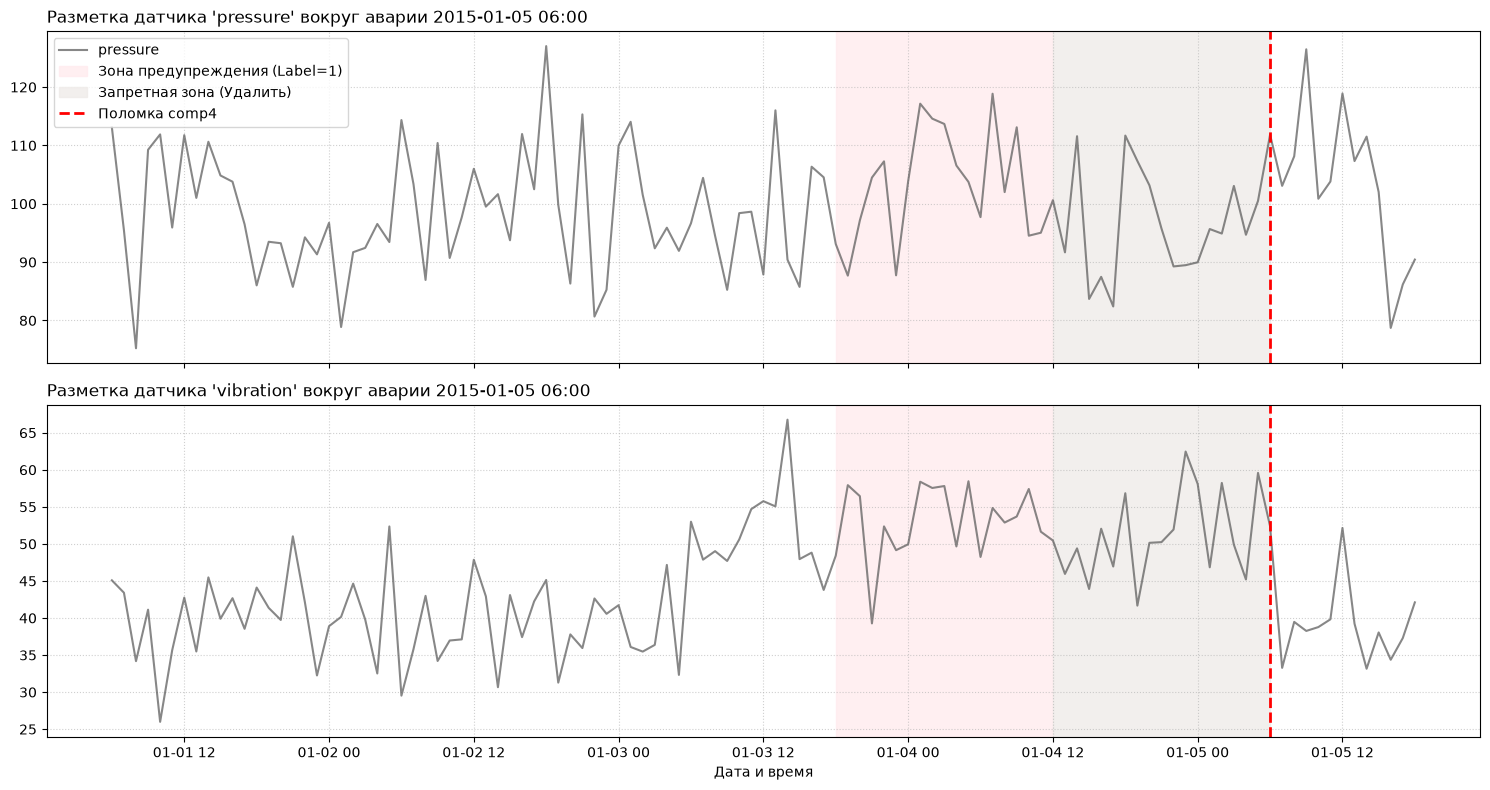

In [22]:
sensors_to_plot = ["pressure", "vibration"]
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(15, 8), sharex=True, dpi=100)

for i, sensor in enumerate(sensors_to_plot):
    ax = axes[i]
    
    # Линия показаний датчика
    ax.plot(m1_slice["datetime"], m1_slice[sensor], color="#555555", alpha=0.7, label=sensor, linewidth=1.5)
    
    # Подсветка Зоны Предупреждения (18-36 часов до аварии) -> LABEL = 1
    ax.axvspan(start_warning_zone, end_warning_zone, color="#ffebee", alpha=0.8, label="Зона предупреждения (Label=1)")
    
    # Подсветка Зоны Удаления (0-18 часов до аварии) -> Убираем из датасета
    ax.axvspan(end_warning_zone, fail_time, color="#efebe9", alpha=0.8, label="Запретная зона (Удалить)")
    
    # Линия самой аварии
    ax.axvline(fail_time, color="red", linestyle="--", linewidth=2, label=f"Поломка {failed_component}")
    
    # Оформление
    ax.set_title(f"Разметка датчика '{sensor}' вокруг аварии {fail_time.strftime('%Y-%m-%d %H:%M')}", fontsize=12, loc='left')
    ax.grid(True, linestyle=":", alpha=0.6)
    
    # Настройка кастомной легенды, чтобы не дублировать элементы
    if i == 0:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles, labels, loc="upper left")

plt.xlabel("Дата и время")
plt.tight_layout()
plt.show()

In [26]:
sensor_cols = ["volt", "rotate", "pressure", "vibration"]
train_machines = list(range(1, 41))
test_machines = list(range(41, 61))

In [43]:
def prepare_dataset(df_telemetry, df_failures, df_errors, machine_list):
    
    # Приведение к datetime и сортировка
    df_telemetry["datetime"] = pd.to_datetime(df_telemetry["datetime"])
    df_failures["datetime"] = pd.to_datetime(df_failures["datetime"])
    df_errors["datetime"] = pd.to_datetime(df_errors["datetime"])

    # Фильтруем данные только для нужной когорты машин
    df_telemetry["datetime"] = pd.to_datetime(df_telemetry["datetime"])
    df_failures["datetime"] = pd.to_datetime(df_failures["datetime"])
    df_errors["datetime"] = pd.to_datetime(df_errors["datetime"])

    # Фильтрация по когорте машин
    df_telemetry = df_telemetry[
        df_telemetry["machineID"].isin(machine_list)
    ].copy()
    df_failures = df_failures[
        df_failures["machineID"].isin(machine_list)
    ].copy()
    df_errors = df_errors[df_errors["machineID"].isin(machine_list)].copy()

    # Сортировка телеметрии
    df_telemetry = df_telemetry.sort_values(["machineID", "datetime"]).reset_index(
        drop=True
    )

    # --------------------------------------
    # ШАГ А. ПОДГОТОВКА И ДЕКОДИРОВАНИЕ ОШИБОК
    # --------------------------------------
    print("Обработка и OHE-кодирование ошибок...")
    # Превращаем виды ошибок (error1, error2...) в отдельные бинарные колонки
    df_errors_ohe = pd.get_dummies(df_errors, columns=["errorID"], prefix="err")

    # Группируем по времени и машине (на случай, если в один час выпало несколько разных ошибок)
    error_cols = [c for c in df_errors_ohe.columns if c.startswith("err_")]
    df_errors_grouped = (
        df_errors_ohe.groupby(["datetime", "machineID"])[error_cols]
        .sum()
        .reset_index()
    )

    # Склеиваем сетку телеметрии с ошибками (left join)
    df_combined = pd.merge(
        df_telemetry,
        df_errors_grouped,
        on=["datetime", "machineID"],
        how="left",
    )
    # Заполняем нулями те часы, где ошибок не происходило
    df_combined[error_cols] = df_combined[error_cols].fillna(0).astype(int)

    # --------------------------------------
    # ШАГ Б. ГЕНЕРАЦИЯ ПРИЗНАКОВ ДАТЧИКОВ (ОКНА НАЗАД)
    # --------------------------------------
    print("Расчет скользящих окон для датчиков...")
    features_list = [df_combined[["datetime", "machineID"]]]

    for w in [WINDOW_SHORT_H, WINDOW_LONG_H]:
        rolling_sensors = df_combined.groupby("machineID")[sensor_cols].rolling(
            window=w, min_periods=w
        )

        mean_df = rolling_sensors.mean().reset_index(level=0, drop=True)
        std_df = rolling_sensors.std().reset_index(level=0, drop=True)
        max_df = rolling_sensors.max().reset_index(level=0, drop=True)

        mean_df.columns = [f"{c}_mean_{w}h" for c in sensor_cols]
        std_df.columns = [f"{c}_std_{w}h" for c in sensor_cols]
        max_df.columns = [f"{c}_max_{w}h" for c in sensor_cols]

        features_list.extend([mean_df, std_df, max_df])

    # --------------------------------------
    # ШАГ В. ГЕНЕРАЦИЯ ПРИЗНАКОВ ОШИБОК (ОКНА НАЗАД)
    # --------------------------------------
    print("Расчет накопительных окон для ошибок...")
    for w in [WINDOW_LONG_H]:  # Ошибки лучше всего копить за длинное окно (24ч)
        # Считаем сумму (количество) ошибок каждого типа за последние 24 часа
        rolling_errors = (
            df_combined.groupby("machineID")[error_cols]
            .rolling(window=w, min_periods=w)
            .sum()
            .reset_index(level=0, drop=True)
        )
        rolling_errors.columns = [f"{c}_count_{w}h" for c in error_cols]
        features_list.append(rolling_errors)

    # Собираем все признаки в единый датафрейм
    full_df = pd.concat(features_list, axis=1)

    # Добавляем базовый сырой вольтаж/вибрацию
    for col in sensor_cols:
        full_df[f"{col}_raw"] = df_combined[col]

    # --------------------------------------
    # ШАГ Г. РАЗМЕТКА ТАРГЕТА И ФИЛЬТРАЦИЯ
    # --------------------------------------
    print("Разметка целевого диапазона...")
    full_df["target"] = 0
    rows_to_drop = pd.Series(False, index=full_df.index)

    for idx, row in df_failures.iterrows():
        machine = row["machineID"]
        fail_time = row["datetime"]

        start_target = fail_time - pd.Timedelta(hours=LEAD_TIME_MAX_HRS)
        end_target = fail_time - pd.Timedelta(hours=LEAD_TIME_MIN_HRS)

        target_mask = (
            (full_df["machineID"] == machine)
            & (full_df["datetime"] >= start_target)
            & (full_df["datetime"] <= end_target)
        )
        full_df.loc[target_mask, "target"] = 1

        too_close_mask = (
            (full_df["machineID"] == machine)
            & (full_df["datetime"] > end_target)
            & (full_df["datetime"] <= fail_time)
        )
        rows_to_drop = rows_to_drop | too_close_mask

    # Очистка: удаляем NaN (первые 24 часа) и запретную зону
    full_df = full_df.dropna().copy()
    full_df = full_df[~rows_to_drop.loc[full_df.index]].reset_index(drop=True)

    # Разделение матрицы
    feature_columns = [
        c
        for c in full_df.columns
        if c not in ["datetime", "machineID", "target"]
    ]
    X = full_df[feature_columns]
    y = full_df["target"]

    print(
        f"Готово! Фичи ошибок добавлены. Объектов: {len(full_df)} (1-класс: {y.sum()})\n"
    )
    return X, y

In [45]:
X_train, y_train = prepare_dataset(telemetry_df, failures_df, errors_df, train_machines)
X_test, y_test = prepare_dataset(telemetry_df, failures_df, errors_df, test_machines)

Обработка и OHE-кодирование ошибок...
Расчет скользящих окон для датчиков...
Расчет накопительных окон для ошибок...
Разметка целевого диапазона...
Готово! Фичи ошибок добавлены. Объектов: 344550 (1-класс: 5244)

Обработка и OHE-кодирование ошибок...
Расчет скользящих окон для датчиков...
Расчет накопительных окон для ошибок...
Разметка целевого диапазона...
Готово! Фичи ошибок добавлены. Объектов: 172456 (1-класс: 2432)



In [32]:
import lightgbm as lgb
from sklearn.metrics import classification_report, precision_recall_curve, auc

In [46]:
num_zeros = (y_train == 0).sum()
num_ones = (y_train == 1).sum()
scale_pos_weight_value = num_zeros / num_ones

print(f"Дисбаланс классов в Train: 0-класс = {num_zeros}, 1-класс = {num_ones}")
print(f"Рекомендуемый scale_pos_weight: {scale_pos_weight_value:.2f}\n")

Дисбаланс классов в Train: 0-класс = 339306, 1-класс = 5244
Рекомендуемый scale_pos_weight: 64.70



In [47]:
model = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    scale_pos_weight=scale_pos_weight_value,
    random_state=42,
    verbosity=-1  # Отключаем лишние логи LightGBM
)

In [48]:
model.fit(X_train, y_train)

,max_depth,6
,learning_rate,0.05
,n_estimators,150
,random_state,42
,scale_pos_weight,np.float64(64.70366132723112)
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [49]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [50]:
print(classification_report(y_test, y_pred, target_names=["Норма (0)", "Предупреждение (1)"]))

                    precision    recall  f1-score   support

         Норма (0)       1.00      0.92      0.96    170024
Предупреждение (1)       0.13      0.89      0.23      2432

          accuracy                           0.92    172456
         macro avg       0.57      0.91      0.59    172456
      weighted avg       0.99      0.92      0.95    172456



In [51]:
precision, recall, _ = precision_recall_curve(y_test, y_prob)
pr_auc = auc(recall, precision)
print(f"PR-AUC (Precision-Recall AUC) на тесте: {pr_auc:.4f}")

PR-AUC (Precision-Recall AUC) на тесте: 0.5340


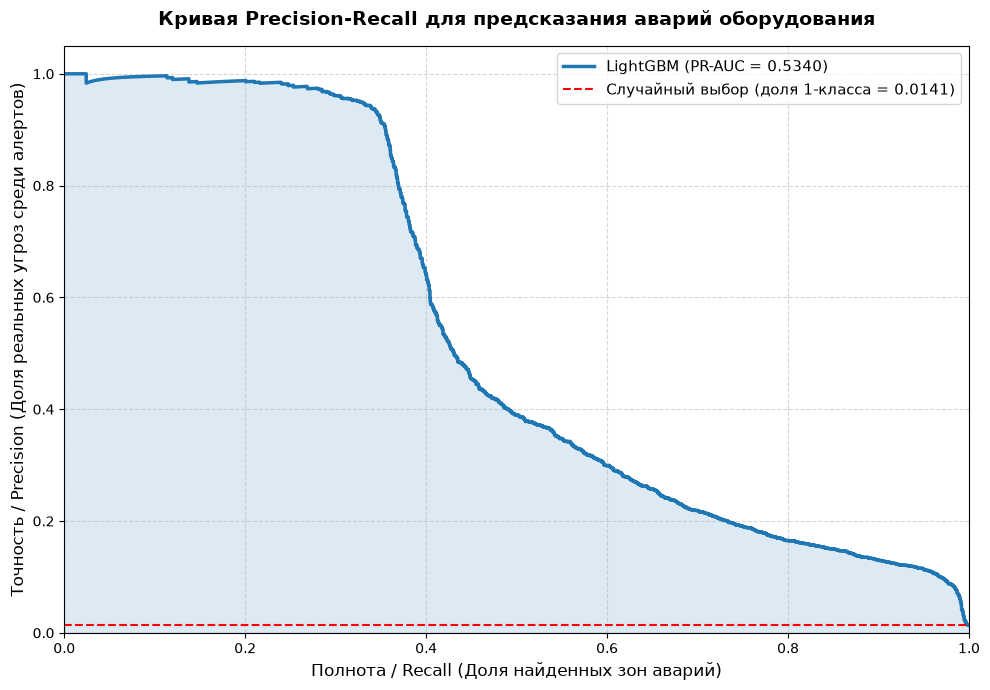

In [52]:
random_classifier_line = sum(y_test) / len(y_test)

# 3. Настройка и построение графика
plt.figure(figsize=(10, 7), dpi=100)

# Строим PR-кривую модели
plt.plot(
    recall,
    precision,
    color="#1f77b4",
    linewidth=2.5,
    label=f"LightGBM (PR-AUC = {pr_auc:.4f})",
)

# Заполняем площадь под кривой полупрозрачным цветом
plt.fill_between(recall, precision, alpha=0.15, color="#1f77b4")

# Строим линию случайного угадывания (бесполезная модель)
plt.axhline(
    y=random_classifier_line,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Случайный выбор (доля 1-класса = {random_classifier_line:.4f})",
)

# Оформление осей и сетки
plt.title(
    "Кривая Precision-Recall для предсказания аварий оборудования",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Полнота / Recall (Доля найденных зон аварий)", fontsize=12)
plt.ylabel("Точность / Precision (Доля реальных угроз среди алертов)", fontsize=12)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", fontsize=11, frameon=True, shadow=False)

# Выводим график
plt.tight_layout()
plt.show()

SyntaxError: invalid syntax (53548651.py, line 1)